# 07 什么时候推送：时段与星期

运营常问：推送、短信该在一天的什么时候发、一周的哪天发？这里看两件事：

1. 流量在一天里怎么分布；
2. **加购之后多大比例会在 24 小时内买下**，这个比例在不同时段、不同星期是否不同。

两个前提（notebook 01）：时间按本地时间 UTC+3；**排除 11-14 ~ 11-17**（购买埋点缺失 + 大促），
否则 11-15（周五）的加购全部「没有买」，会把周五的转化率算得极低。

In [1]:
from nbutils import *
import numpy as np

EXCLUDE = "event_date NOT BETWEEN '2019-11-14' AND '2019-11-17'"

## 1. 一天里的流量和转化

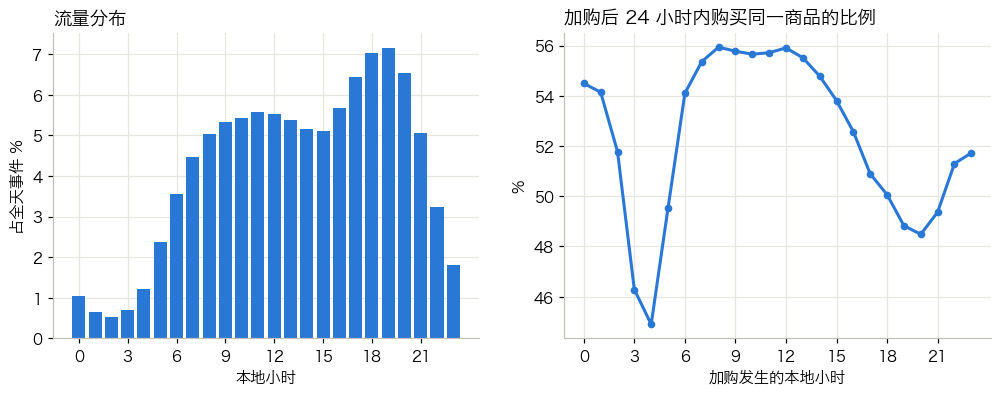

In [2]:
cart = q(f"""
    WITH carts AS (
        SELECT row_number() OVER () AS cid, user_id, product_id, event_time, event_hour, dayofweek(event_date) AS weekday
        FROM dwd_events WHERE event_type = 'cart' AND {EXCLUDE}
    ),
    p AS (SELECT user_id, product_id, event_time AS pt FROM dwd_events WHERE event_type = 'purchase' AND {EXCLUDE}),
    matched AS (
        SELECT c.cid FROM carts c JOIN p
          ON p.user_id = c.user_id AND p.product_id = c.product_id
         AND p.pt >= c.event_time AND p.pt <= c.event_time + INTERVAL 24 HOUR
        GROUP BY 1
    )
    SELECT user_id, event_hour, weekday, COUNT(*) AS carts, COUNT(m.cid) AS bought
    FROM carts c LEFT JOIN matched m USING (cid)
    GROUP BY 1, 2, 3
""")
traffic = q(f"SELECT event_hour, COUNT(*) AS events FROM dwd_events WHERE {EXCLUDE} GROUP BY 1 ORDER BY 1")
by_hour = cart.groupby("event_hour")[["carts", "bought"]].sum()
by_hour["conv"] = by_hour.bought / by_hour.carts

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(traffic.event_hour, traffic.events / traffic.events.sum() * 100, color=PALETTE[0], width=0.8)
axes[0].set(xlabel="本地小时", ylabel="占全天事件 %", title="流量分布", xticks=range(0, 24, 3))
axes[1].plot(by_hour.index, by_hour.conv * 100, color=PALETTE[0], marker="o", markersize=4)
axes[1].set(xlabel="加购发生的本地小时", ylabel="%", title="加购后 24 小时内购买同一商品的比例", xticks=range(0, 24, 3))
plt.show()

In [3]:
SLOTS = [("早上 6–11 点", range(6, 11)), ("中午 11–14 点", range(11, 14)), ("下午 14–18 点", range(14, 18)),
         ("晚上 18–22 点", range(18, 22)), ("深夜 22–6 点", [22, 23, 0, 1, 2, 3, 4, 5])]
hour_to_slot = {h: name for name, hours in SLOTS for h in hours}
cart["slot"] = cart.event_hour.map(hour_to_slot)
slot = cart.groupby("slot")[["carts", "bought"]].sum().loc[[n for n, _ in SLOTS]]
slot["加购后24小时购买率"] = slot.bought / slot.carts
slot["流量占比"] = traffic.assign(slot=traffic.event_hour.map(hour_to_slot)).groupby("slot").events.sum() / traffic.events.sum()

# 同一用户在不同时段的差异：只看在 ≥2 个时段都加购过的用户，每个时段的转化率减去他自己的平均
us = cart.groupby(["user_id", "slot"])[["carts", "bought"]].sum().reset_index()
us["conv"] = us.bought / us.carts
multi = us[us.groupby("user_id").slot.transform("nunique") >= 2].copy()
multi["dev"] = multi.conv - multi.groupby("user_id").conv.transform("mean")
slot["同一用户内的差异"] = multi.groupby("slot").dev.mean()
print(f"同一用户比较：{multi.user_id.nunique():,} 个在两个以上时段都加购过的用户")
slot[["流量占比", "carts", "加购后24小时购买率", "同一用户内的差异"]].rename(columns={"carts": "加购次数"}) \
    .style.format({"流量占比": "{:.1%}", "加购次数": "{:,}", "加购后24小时购买率": "{:.1%}", "同一用户内的差异": "{:+.1%}"})

同一用户比较：219,107 个在两个以上时段都加购过的用户


,流量占比,加购次数,加购后24小时购买率,同一用户内的差异
slot,,,,
早上 6–11 点,23.8%,"680,337",55.5%,+1.0%
中午 11–14 点,16.5%,"499,770",55.7%,+0.7%
下午 14–18 点,22.4%,"553,159",53.1%,-0.0%
晚上 18–22 点,25.8%,"456,247",49.2%,-1.2%
深夜 22–6 点,11.5%,"199,486",50.6%,-1.6%


- **流量**：晚上 7 点前后最高，凌晨 2–5 点最低；
- **转化**：早上和中午加购的，55% 会在 24 小时内买下；晚上降到 49%，深夜 51%。早晚差 6 个百分点；
- **但大部分差距来自「不同的人」**：同一个用户，早上加购比他自己的平均高 1 个点，晚上低 1.2 个点，自身的早晚差只有 2 个点左右。
  晚上转化低，主要是晚上来逛的人本来就更「随便看看」，而不是同一个人到了晚上就不买了。

**对推送的含义**：

- 「提醒下单」类的推送（购物车提醒、降价提醒）放在**上午**，用户这时候决策更快；
- 晚上流量大，适合内容种草、拉加购，但不要指望当晚成交——晚上加购的有一半是第二天及以后才买；
- 早晚差异只有几个点，**推送时间不是召回成败的关键，触达谁、什么时候（沉默第几天）更重要**（notebook 04）。

## 2. 星期几

In [4]:
wd = cart.groupby("weekday")[["carts", "bought"]].sum()
wd["加购后24小时购买率"] = wd.bought / wd.carts
wd.index = ["周日", "周一", "周二", "周三", "周四", "周五", "周六"]
wd = wd.loc[["周一", "周二", "周三", "周四", "周五", "周六", "周日"]]
wd.rename(columns={"carts": "加购次数"})[["加购次数", "加购后24小时购买率"]] \
  .style.format({"加购次数": "{:,}", "加购后24小时购买率": "{:.1%}"})

,加购次数,加购后24小时购买率
周一,"358,625",53.4%
周二,"360,677",52.5%
周三,"358,049",53.4%
周四,"287,085",54.7%
周五,"386,944",53.6%
周六,"354,885",53.0%
周日,"282,734",53.1%


一周七天的加购转化都在 52.5%–54.7% 之间，**星期几几乎没有影响**。

这一点值得强调：如果不排除 11-14 ~ 11-17，算出来会是**周五 25%、周六 39%、周日 58%**——
周五、周六碰上了购买埋点缺失（11-15、11-16 的加购大多「没有买」），周日碰上了大促当天（11-17）。
「周日最适合催单、周五最差」这种结论很容易从脏数据里读出来，而且听上去很像真的。